<h1 align="center">Física Computacional.</h1>
<h1 align="center">Semestre 2027-1</h1>

<h2>Karla Edith Santiago Pérez </h2> 

---
<h2>Profesores: </h2> 

### Sergio A. Alcalá Corona
### Rodrigo Vega Vilchis
### Joel Gómez Uribe
---


<h1 align="center">Programación para la física computacional</h1> 

## Práctica 5    Métodos de Diferenciación Numérica


---

# 1. Diferenciación numérica 

Crea una función $f(x)$ que devuelva $1 + \frac{1}{2} \tanh 2x$, luego usa diferencias centrales para calcular la derivada de la función en el intervalo $-2 \le x \le 2$.

Después, calcula la derivada analíticamente y haz una gráfica con tu resultado numérico y la respuesta analítica en el mismo gráfico. Puede resultar útil graficar la respuesta exacta como líneas y la numérica como puntos.

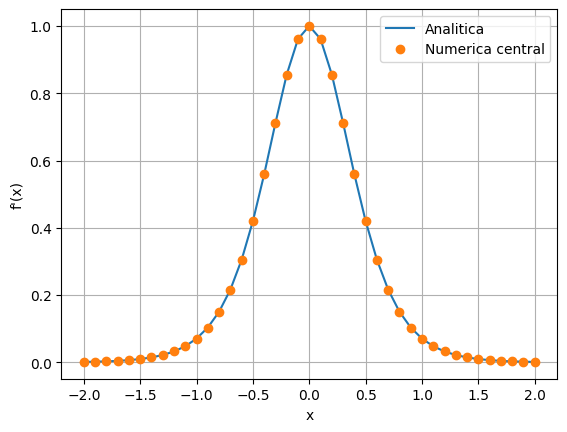

In [67]:
# Fase 1
import math  # Importo math porque uso tanh para la funcion
import numpy as np  # Importo numpy porque genero el vector de x
import matplotlib.pyplot as plt  # Importo pyplot para graficar

# Fase 2: Defino los parametros 
h = 0.01  # Defino h = 0.01 como paso para la diferencia central
xs = np.linspace(-2, 2, 41)  # Genero 41 puntos entre -2 y 2

# Fase 3: Defino la funcion que voy a derivar
def f(x):  # Defino la funcion f(x)
    return 1 + 0.5 * math.tanh(2 * x)  

# Fase 4: Defino la derivada analitica
def df_analitica(x):  # Defino la derivada analitica
    return 1 - math.tanh(2 * x) ** 2 

# Fase 5: Calculo la derivada numerica con diferencias centrales
deriv_num = []  # Creo una lista vacia para guardar la derivada numerica
for x in xs:  # Recorro cada punto x del intervalo
    deriv_num.append((f(x + h) - f(x - h)) / (2 * h)) 

# Fase 6: Calculo la derivada analitica en los mismos puntos
deriv_ana = []  # Creo una lista vacia para guardar la derivada analitica
for x in xs:  # Recorro cada punto x del intervalo
    deriv_ana.append(df_analitica(x))  # Calculo el valor exacto en ese x

# Fase 7: Grafico ambos resultados en el mismo grafico
plt.plot(xs, deriv_ana, label='Analitica')  # Grafico la analitica como linea
plt.plot(xs, deriv_num, 'o', label='Numerica central')  # Grafico la numerica como puntos
plt.xlabel('x')  #  eje x
plt.ylabel("f'(x)")  #  eje y
plt.legend()  
plt.grid(True)  
plt.show()  

# 2. Campo eléctrico de una distribución de cargas 

Distribución de cargas, cálculo del campo eléctrico a partir del potencial eléctrico $\phi$ y luego su gradiente.

Carga puntual $q$ en el origen:
$$\phi = \frac{q}{4\pi\epsilon_0 r}, \quad \mathbf{E} = -\nabla \phi$$

**(a)** Dos cargas, $+1\, \text{C}$ y $-1\, \text{C}$, separadas $10\, \text{cm}$.

Calcular el potencial eléctrico resultante en un plano cuadrado de $1\, \text{m} \times 1\, \text{m}$ que rodea las cargas y pasa a través de ellas, en una cuadrícula de puntos espaciados a $1\, \text{cm}$.

Calcular el campo eléctrico usando un gradiente y visualizar el potencial con un gráfico de densidad.

In [112]:
# Fase 2: Defino las constantes fisicas y las cargas
eps0 = 8.854187817e-12  # Defino epsilon0, la permitividad del vacio
k = 1 / (4 * np.pi * eps0)  # k = 1/(4*pi*eps0) = 9e9
q_mas = 1.0  # la carga positiva +1 C
q_menos = -1.0  #  la carga negativa -1 C

In [113]:
# Fase 3: Defino las posiciones de las cargas
x_mas = -0.05  #  + en x = -0.05 m
x_menos = 0.05  # - en x = +0.05 m
y_cargas = 0.0  # Pongo ambas cargas en y = 0

In [114]:

# Fase 4: Creo la malla de puntos donde calculo el potencial
xs = np.linspace(-0.5, 0.5, 101)  #  101 puntos en x de -0.5 a 0.5 m
ys = np.linspace(-0.5, 0.5, 101)  #  101 puntos en y de -0.5 a 0.5 m
X, Y = np.meshgrid(xs, ys)  #  malla 2D con todas las combinaciones (x,y)

In [115]:
# Fase 5: Calculo las distancias a cada carga
r_mas = np.sqrt((X - x_mas) ** 2 + (Y - y_cargas) ** 2)  # Calculo r+ = distancia a la carga +
r_menos = np.sqrt((X - x_menos) ** 2 + (Y - y_cargas) ** 2)  # Calculo r- = distancia a la carga -

In [116]:
# Fase 6: Evito la singularidad en las cargas
r_mas = np.maximum(r_mas, 0.005)  # Limito r+ a un minimo de 0.005 m para no dividir entre cero
r_menos = np.maximum(r_menos, 0.005)  # Limito r- a un minimo de 0.005 m para no dividir entre cero

In [117]:
# Fase 7: Calculo el potencial total por superposicion
phi = k * (q_mas / r_mas + q_menos / r_menos)  # Calculo phi = k*(q+/r+ + q-/r-)

# Fase 8: Recorto el potencial para poder visualizarlo
phi_muestra = np.clip(phi, -2e11, 2e11)  # Recorto phi entre -2e11 y 2e11 para que se vea el contraste

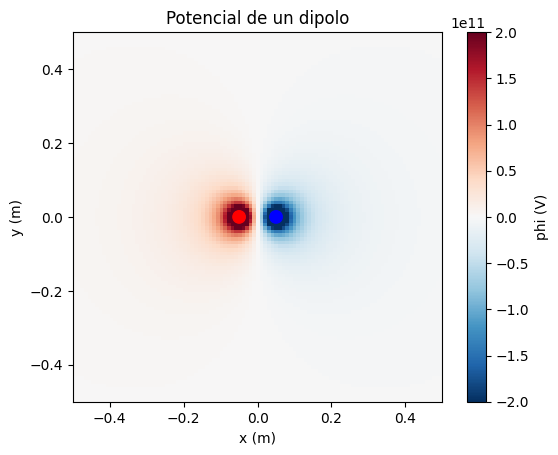

In [118]:


# Fase 9: Grafico el potencial como grafico de densidad
plt.imshow(phi_muestra, extent=[-0.5, 0.5, -0.5, 0.5], origin='lower', cmap='RdBu_r')  # Muestro phi como imagen de colores
plt.colorbar(label='phi (V)')  # Muestro la barra de colores con unidades
plt.scatter([x_mas, x_menos], [y_cargas, y_cargas], c=['red', 'blue'], s=80)  # Marco las cargas con puntos rojo y azul
plt.xlabel('x (m)')  # Pongo el nombre del eje x
plt.ylabel('y (m)')  # Pongo el nombre del eje y
plt.title('Potencial de un dipolo')  # Pongo el titulo de la grafica
plt.show()  # Muestro la grafica

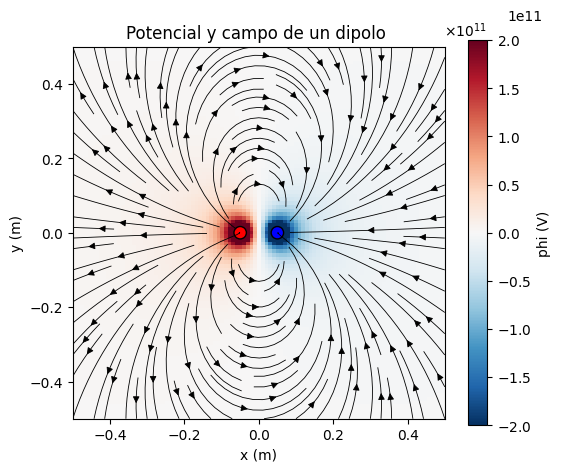

In [119]:
# FASE 8: Recorto el potencial para visualizar
phi_muestra = np.clip(phi, -2e11, 2e11)
# FASE 8b: Calculo el campo electrico E = -grad phi
# np.gradient me da dphi/dy , dphi/dx con diferencias centrales 
dphi_dy, dphi_dx = np.gradient(phi, ys, xs)  # calculo gradiente, me da derivadas parciales 
Ex = -dphi_dx  # pongo Ex = -dphi/dx
Ey = -dphi_dy  # pongo Ey = -dphi/dy

# FASE 9: Grafico potencial + lineas de campo como en el guion
plt.figure(figsize=(6,5)) 
plt.imshow(phi_muestra, extent=[-0.5,0.5,-0.5,0.5], origin='lower', cmap='RdBu_r') # grafico densidad phi 
cbar = plt.colorbar(label='phi (V)')
cbar.formatter.set_powerlimits((0,0))
cbar.formatter.set_useMathText(True)
plt.gcf().text(0.85, 0.92, '1e11', fontsize=10) #  si no sale el 1e11 arriba
plt.streamplot(X, Y, Ex, Ey, color='k', density=1.2, linewidth=0.6, arrowsize=1) #  lineas de E
plt.scatter([x_mas, x_menos], [y_cargas, y_cargas], c=['red','blue'], s=80, edgecolors='k') # marco cargas
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Potencial y campo de un dipolo ')
plt.show()

# 2. (b) Campo eléctrico en el plano $xy$

Calcular las derivadas parciales del potencial con respecto a $x$ y $y$, para encontrar el campo eléctrico en el plano $xy$ y visualizar dicho campo.

El campo eléctrico tiene magnitud y dirección. Visualización propuesta:

- Dos gráficos de densidad: uno para la magnitud y otro para la dirección.
- Dirección con esquema de color `"hsv"` en `pylab`: arcoiris que pasa por todos los colores y comienza y termina en el mismo tono de rojo, adecuado para representar direcciones o ángulos que dan la vuelta al círculo completo y terminan donde comenzaron.

Visualización más sofisticada: usar el objeto de flecha del paquete `visual`, dibujando una cuadrícula de flechas con la dirección y la longitud elegidas para representar el campo.


In [121]:

# FASE 1: Defino las constantes fisicas y las cargas del problema
epsilon_0 = 8.854187817e-12  # Defino la permitividad del vacio en F/m
k = 1 / (4 * np.pi * epsilon_0)  # Calculo la constante de Coulomb k 
q1 = 1.0  # Defino la carga 1, +1 C
q2 = -1.0  # Defino la carga 2, -1 C
x1, y1 = -0.25, 0.0  #  posicion de la carga 1, a la izquierda
x2, y2 = 0.25, 0.0  # posicion de la carga 2, a la derecha

In [ ]:
# FASE 2: Creo la malla de observacion donde calculo el potencial y el campo
#  El enunciado pide puntos espaciados a 1 cm en 1 m x 1 m.
paso_obs = 0.01  # Defino el espaciamiento de observacion, 1 cm en metros
x_obs = np.arange(-0.5, 0.5 + paso_obs, paso_obs)  # Creo el vector x de observacion de -0.5 a 0.5 m
y_obs = np.arange(-0.5, 0.5 + paso_obs, paso_obs)  # Creo el vector y de observacion de -0.5 a 0.5 m
X, Y = np.meshgrid(x_obs, y_obs)  # Creo la malla 2D X,Y con todos los puntos donde observo

In [123]:
# FASE 3: Calculo el potencial phi con la formula analitica de cargas puntuales
# No integro aqui porque las cargas son puntuales,
# uso superposicion: phi = phi1 + phi2.
r1 = np.sqrt((X - x1)**2 + (Y - y1)**2)  # distancia r1 de cada punto a la carga 1
r2 = np.sqrt((X - x2)**2 + (Y - y2)**2)  # Calculo la distancia r2 de cada punto a la carga 2
r1 = np.maximum(r1, 1e-3)  # Evito la division entre cero, limito r1 a minimo 1 mm
r2 = np.maximum(r2, 1e-3)  # Evito la division entre cero, limito r2 a minimo 1 mm
phi = k * (q1 / r1 + q2 / r2)  # Calculo phi con superposicion, phi = k * (q1/r1 + q2/r2)

In [124]:
# FASE 4: Calculo el campo electrico con diferenciacion numerica central
#  E = - gradiente(phi).
# Uso diferencia central porque es O(h^2), mas precisa que adelante/atras que son O(h).
h = paso_obs  # Defino h igual al espaciamiento de la malla, 1 cm, porque phi solo existe ahi
Ex = np.zeros_like(phi)  # Creo la matriz vacia Ex para el campo en x
Ey = np.zeros_like(phi)  # Creo la matriz vacia Ey para el campo en y
Ex[1:-1, 1:-1] = -(phi[1:-1, 2:] - phi[1:-1, :-2]) / (2 * h)  # Calculo Ex con diferencia central en x y cambio el signo
Ey[1:-1, 1:-1] = -(phi[2:, 1:-1] - phi[:-2, 1:-1]) / (2 * h)  # Calculo Ey con diferencia central en y y cambio el signo
magnitud = np.sqrt(Ex**2 + Ey**2)  # Calculo la magnitud del campo |E| = sqrt(Ex^2 + Ey^2)


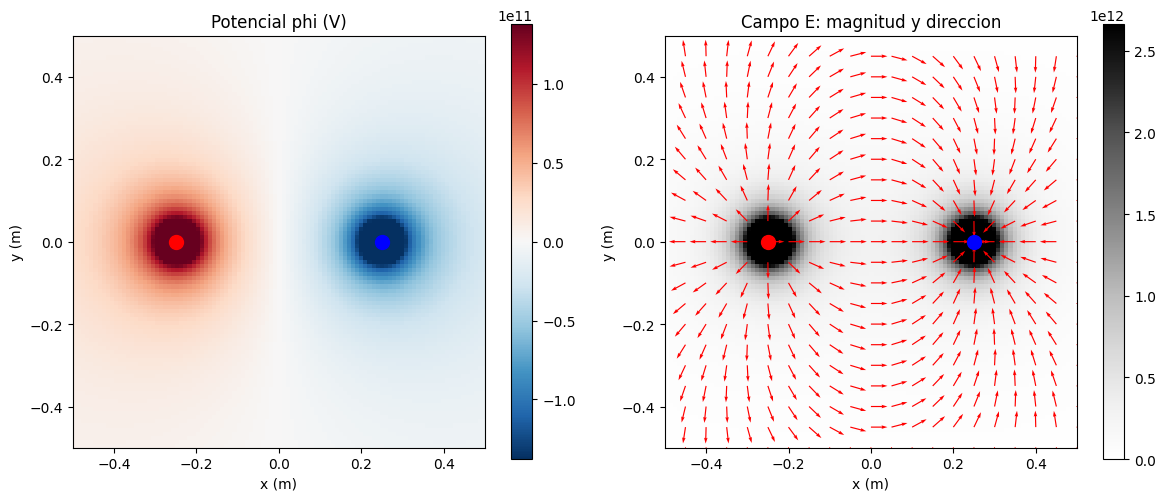

In [125]:
# FASE 5: Grafico el potencial y el campo

# El enunciado pide magnitud en escala de grises y direccion con flechas.
vmax_phi = np.percentile(np.abs(phi), 98)  # Calculo el percentil 98 de |phi| para fijar la escala de color sin que un pico la domine
vmax_E = np.percentile(magnitud, 98)  # Calculo el percentil 98 de |E| para fijar la escala de color sin que un pico la domine
norm = np.sqrt(Ex**2 + Ey**2) + 1e-12  #  norma de E mas un epsilon para no dividir entre cero
Ux = Ex / norm  # Normalizo la componente x, solo me quedo con la direccion
Uy = Ey / norm  # Normalizo la componente y, solo me quedo con la direccion
fig, ax = plt.subplots(1, 2, figsize=(12, 5))  # Creo una figura con dos graficos lado a lado
im0 = ax[0].imshow(phi, extent=[-0.5, 0.5, -0.5, 0.5], origin='lower', cmap='RdBu_r', vmin=-vmax_phi, vmax=vmax_phi)  # Grafico el potencial con colores simetricos rojo-azul
ax[0].plot(x1, y1, 'o', color='red', markersize=10)  # carga positiva con un punto rojo
ax[0].plot(x2, y2, 'o', color='blue', markersize=10)  # carga negativa con un punto azul
ax[0].set_title('Potencial phi (V)')  # titulo del potencial
ax[0].set_xlabel('x (m)')  #eje x
ax[0].set_ylabel('y (m)')  # eje y
fig.colorbar(im0, ax=ax[0])  # Agrego la barra de colores del potencial
im1 = ax[1].imshow(magnitud, extent=[-0.5, 0.5, -0.5, 0.5], origin='lower', cmap='Greys', vmin=0, vmax=vmax_E)  # Grafico la magnitud del campo en escala de grises acromatica
ax[1].quiver(X[::5, ::5], Y[::5, ::5], Ux[::5, ::5], Uy[::5, ::5], color='red', scale=25)  # Dibujo las flechas de direccion cada 5 puntos, normalizadas para que no exploten
ax[1].plot(x1, y1, 'o', color='red', markersize=10)  # Dibujo la carga positiva en el grafico del campo
ax[1].plot(x2, y2, 'o', color='blue', markersize=10)  # Dibujo la carga negativa en el grafico del campo
ax[1].set_title('Campo E: magnitud y direccion')  # titulo del campo
ax[1].set_xlabel('x (m)')  #eje x
ax[1].set_ylabel('y (m)')  # eje y
fig.colorbar(im1, ax=ax[1])  # Agrego la barra de colores de la magnitud
plt.tight_layout()  # Ajusto los graficos para que no se corten los titulos
plt.show()  # Muestro los graficos

# 2. (c) Distribución continua de carga

Distribución continua de carga sobre un cuadrado de $L \times L$. Densidad de carga en $\text{C}/\text{m}^2$:
$$\sigma(x,y) = q_0 \sin\frac{2\pi x}{L} \sin\frac{2\pi y}{L}$$

Calcular y visualizar el campo eléctrico resultante en puntos espaciados a $1\, \text{cm}$ en $1$ metro cuadrado del plano $xy$, para $L = 10\, \text{cm}$.

Distribución de carga centrada en el medio del área visualizada y $q_0 = 100\, \frac{\text{C}}{\text{m}^2}$.

Realizar una integral doble sobre $x$ y $y$, luego diferenciar el potencial respecto a la posición para obtener el campo eléctrico. Elegir cualquier método de integración apropiado para las integrales.

In [129]:

from numpy.polynomial.legendre import leggauss  # Importo leggauss para obtener nodos y pesos de Gauss-Legendre

In [130]:
# FASE 1: Defino las constantes fisicas y los parametros del problema
epsilon_0 = 8.854187817e-12  # Defino la permitividad del vacio en F/m
k = 1 / (4 * np.pi * epsilon_0)  # Calculo la constante de Coulomb k 
L = 0.10  # Defino el lado de la lamina, 10 cm lo paso a 0.10 m
q0 = 100e-6  # Defino la densidad maxima, 
a_fuente = -L / 2  # Defino el extremo inferior de la lamina en x', -L/2
b_fuente = L / 2  # Defino el extremo superior de la lamina en x', +L/2

In [131]:

# FASE 2: Creo la malla de observacion donde calculo el potencial
#  El enunciado pide puntos espaciados a 1 cm en 1 m x 1 m.
paso_obs = 0.01  # Defino el espaciamiento de observacion, 1 cm en metros
x_obs = np.arange(-0.5, 0.5 + paso_obs, paso_obs)  # Creo el vector x de observacion de -0.5 a 0.5 m
y_obs = np.arange(-0.5, 0.5 + paso_obs, paso_obs)  # Creo el vector y de observacion de -0.5 a 0.5 m
X, Y = np.meshgrid(x_obs, y_obs)  #  malla 2D X,Y con todos los puntos donde observo
phi = np.zeros_like(X)  #matriz vacia phi donde guardo el potencial

In [132]:
# FASE 3: Obtengo los nodos y pesos de Gauss-Legendre y los reescalo a la lamina
# Los puntos no son equidistantes, son las raices de P_N.
# Los reescalo de [-1,1] a [a,b]
N_gl = 40  # Defino N = 40 puntos de Gauss por cada eje, 
t, w = leggauss(N_gl)  # Obtengo los nodos t en [-1,1] y los pesos w de Legendre
centro = (b_fuente + a_fuente) / 2  # Calculo el centro del intervalo [a,b], aqui es 0
mitad = (b_fuente - a_fuente) / 2  # Calculo la mitad del intervalo [a,b], aqui es L/2
xp = centro + mitad * t  # Reescalo los nodos a x' en [-L/2, L/2]
yp = centro + mitad * t  # Reescalo los nodos a y' en [-L/2, L/2]
wp = mitad * w  # Reescalo los pesos a w' = (b-a)/2 * w
Xp, Yp = np.meshgrid(xp, yp)  # Creo la malla 2D de puntos de Gauss Xp,Yp
Wx, Wy = np.meshgrid(wp, wp)  # Creo la malla 2D de pesos Wx,Wy
W2D = Wx * Wy  # Calculo el peso 2D como producto de pesos, w'_i * w'_j

In [133]:
# FASE 4: Calculo la densidad de carga sigma en los puntos de Gauss
#  Evaluo la funcion que voy a integrar en los puntos de Gauss, no en puntos equidistantes.
sigma = q0 * np.sin(2 * np.pi * (Xp + L/2) / L) * np.sin(2 * np.pi * (Yp + L/2) / L)  # Calculo sigma(x',y') con la formula del enunciado

# FASE 5: Calculo el potencial con la integral doble de Gauss-Legendre
#  phi = k * integral doble sigma / r dx' dy'. No tiene primitiva simple,
# por eso la aproximo con suma ponderada de Gauss, que es la mas precisa con pocos puntos.
for i in range(len(y_obs)):  # Recorro cada renglon de la malla de observacion
    for j in range(len(x_obs)):  # Recorro cada columna de la malla de observacion
        r = np.sqrt((X[i, j] - Xp)**2 + (Y[i, j] - Yp)**2)  # Calculo la distancia r entre el punto de observacion y cada punto de Gauss
        phi[i, j] = k * np.sum(W2D * sigma / r)  # Sumo W2D * sigma / r y multiplico por k, esta es la integral de Gauss

In [134]:

# FASE 6: Calculo el campo electrico con diferenciacion numerica central
#  E = - gradiente(phi).
# Uso diferencia central porque es O(h^2), mas precisa que adelante/atras que son O(h).
h = paso_obs  # Defino h igual al espaciamiento de la malla, 1 cm, porque phi solo existe ahi
Ex = np.zeros_like(phi)  #  matriz vacia Ex para el campo en x
Ey = np.zeros_like(phi)  #  matriz vacia Ey para el campo en y
Ex[1:-1, 1:-1] = -(phi[1:-1, 2:] - phi[1:-1, :-2]) / (2 * h)  # Ex con diferencia central en x y cambio el signo
Ey[1:-1, 1:-1] = -(phi[2:, 1:-1] - phi[:-2, 1:-1]) / (2 * h)  #  Ey con diferencia central en y y cambio el signo
magnitud = np.sqrt(Ex**2 + Ey**2)  # Calculo la magnitud del campo |E| = sqrt(Ex^2 + Ey^2)

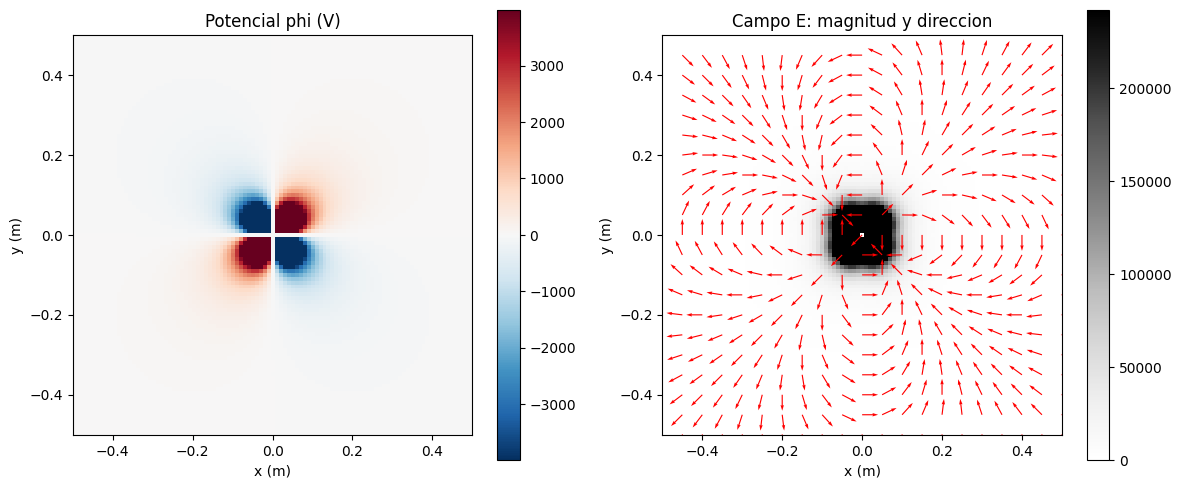

In [135]:
# FASE 7: Grafico el potencial y el campo
vmax_phi = np.percentile(np.abs(phi), 98)  # Calculo el percentil 98 de |phi| para fijar la escala de color sin que un pico la domine
vmax_E = np.percentile(magnitud, 98)  # Calculo el percentil 98 de |E| para fijar la escala de color sin que un pico la domine
norm = np.sqrt(Ex**2 + Ey**2) + 1e-12  # Calculo la norma de E mas un epsilon para no dividir entre cero
Ux = Ex / norm  # Normalizo la componente x, solo me quedo con la direccion
Uy = Ey / norm  # Normalizo la componente y, solo me quedo con la direccion
fig, ax = plt.subplots(1, 2, figsize=(12, 5))  # Creo una figura con dos graficos lado a lado
im0 = ax[0].imshow(phi, extent=[-0.5, 0.5, -0.5, 0.5], origin='lower', cmap='RdBu_r', vmin=-vmax_phi, vmax=vmax_phi)  # Grafico el potencial con colores simetricos rojo-azul
ax[0].set_title('Potencial phi (V)')  #  titulo del potencial
ax[0].set_xlabel('x (m)')  #  eje x
ax[0].set_ylabel('y (m)')  #  eje y
fig.colorbar(im0, ax=ax[0])  # Agrego la barra de colores del potencial
im1 = ax[1].imshow(magnitud, extent=[-0.5, 0.5, -0.5, 0.5], origin='lower', cmap='Greys', vmin=0, vmax=vmax_E)  # Grafico la magnitud del campo en escala de grises acromatica
ax[1].quiver(X[::5, ::5], Y[::5, ::5], Ux[::5, ::5], Uy[::5, ::5], color='red', scale=25)  # Dibujo las flechas de direccion cada 5 puntos, normalizadas para que no exploten
ax[1].set_title('Campo E: magnitud y direccion')  # titulo del campo
ax[1].set_xlabel('x (m)')  #  eje x
ax[1].set_ylabel('y (m)')  #  eje y
fig.colorbar(im1, ax=ax[1])  # Agrego la barra de colores de la magnitud
plt.tight_layout()  # Ajusto los graficos para que no se corten los titulos

## 3. Procesamiento de imágenes y STM 
### Idea física

Cuando la luz incide sobre una superficie, lo que cae por unidad de área no depende solo de lo fuerte que es la luz, sino del ángulo con el que pega.

Si la luz forma un ángulo $\theta$ con la normal, solo "ve" una fracción $\cos\theta$ del área real. Por eso la intensidad es:

$$ I = |a| \cos\theta $$

donde $|a|$ es la intensidad bruta de la luz.

### Superficie y normal

Conozco la altura de las montañas $w(x,y)$ en función de la posición en el plano. La superficie es:

$$ z = w(x,y) \quad \text{o} \quad w(x,y) - z = 0 $$

El vector normal $\vec{v}$ a la superficie es el gradiente de $w(x,y)-z$:

$$ \vec{v} = \nabla[w(x,y)-z] = \begin{pmatrix} \partial w / \partial x \\ \partial w / \partial y \\ -1 \end{pmatrix} $$

- $\partial w / \partial x$ = pendiente en $x$
- $\partial w / \partial y$ = pendiente en $y$
- $-1$ = componente en $z$

### Intensidad con producto punto

Si la luz entrante es un vector $\vec{a}$ con magnitud igual a la intensidad, el producto escalar es:

$$ \vec{a} \cdot \vec{v} = |\vec{a}| \, |\vec{v}| \cos\theta $$

Despejo $\cos\theta$ y queda la intensidad de iluminación:

$$ I = |\vec{a}| \cos\theta = \frac{\vec{a} \cdot \vec{v}}{|\vec{v}|} = \frac{a_x (\partial w / \partial x) + a_y (\partial w / \partial y) - a_z}{\sqrt{(\partial w / \partial x)^2 + (\partial w / \partial y)^2 + 1}} $$

### Caso simple: luz horizontal

Tomo luz horizontal de intensidad unitaria, en ángulo $\phi$ en sentido contrario a las manecillas del reloj desde el eje este-oeste:

$$ \vec{a} = (\cos\phi, \sin\phi, 0) $$

La fórmula se simplifica a:

$$ I = \frac{\cos\phi \, (\partial w / \partial x) + \sin\phi \, (\partial w / \partial y)}{\sqrt{(\partial w / \partial x)^2 + (\partial w / \partial y)^2 + 1}} $$

Conclusión: si calculo las derivadas de $w(x,y)$ y sé $\phi$, ya puedo calcular $I$ en cualquier punto. $I$ va de $-1$ a $+1$.

---

### Datos

| Archivo | Qué es | Forma | $h$ | $\phi$ |
| :--- | :--- | :--- | :--- | :--- |
| `altitudes.txt` | Altura de la Tierra $w(x,y)$ en metros | $508 \times 1024$ | $30000$ m | $45°$ |
| `stm.txt` | Altura de superficie de silicio (111) medida con STM, en unidades arbitrarias | $663 \times 676$ | $2.5$ u.a. | $45°$ |

STM = microscopio de efecto túnel. Mide la forma a nivel atómico recorriendo una punta afilada sobre la superficie y midiendo la corriente de túnel en cada posición. El archivo `stm.txt` es la rejilla de alturas $w(x,y)$ que sale de esa medición.

### Método numérico

Uso diferencias centrales en el interior, error $O(h^2)$:

$$ \frac{\partial w}{\partial x} \approx \frac{w(x+h)-w(x-h)}{2h}, \quad \frac{\partial w}{\partial y} \approx \frac{w(y+h)-w(y-h)}{2h} $$

En los bordes uso hacia adelante / hacia atrás, error $O(h)$, porque no tengo vecino de un lado. En código lo hago con `np.gradient(w, h, h)` o a mano con rebanado.



### (a)

El archivo adjunto `altitudes.txt` contiene la altura $w(x,y)$ en metros sobre el nivel del mar de la superficie de la Tierra, en una cuadrícula de puntos $(x,y)$. Escribe un programa que lea este archivo y almacene los datos en una matriz. Luego calcula las derivadas $\partial w / \partial x$ y $\partial w / \partial y$ en cada punto de la cuadrícula. Explica qué método utilizaste para calcularlos y por qué. Para calcular las derivadas, necesitarás saber el valor de $h$, la distancia entre puntos de la cuadrícula, que es de aproximadamente $30000$ m en este caso.

In [155]:
# FASE 0: Importo las librerias 
import numpy as np  # Importo numpy para trabajar con arreglos y operaciones vectoriales
import matplotlib.pyplot as plt  # Importo pyplot para graficar y verificar que las derivadas salen bien

In [156]:
# FASE 1: Cargo el archivo de alturas como matriz w(x,y)
w = np.loadtxt('altitudes.txt')  # Cargo el archivo altitudes.txt y lo guardo como matriz w

In [157]:
w_stm = np.loadtxt('stm.txt')  # Cargo el archivo stm.txt y lo guardo como matriz w_stm

In [158]:

# FASE 2: Defino el espaciamiento real entre puntos y reviso el tamano de la matriz
# El enunciado dice que la distancia entre puntos es 30,000 m.
# Si uso h = 1, la derivada me sale 30,000 veces mas grande y sale mal.
h = 30000.0  # Defino h = 30000 m, es la distancia real entre dos puntos vecinos de la cuadricula
ny, nx = w.shape  # Obtengo el tamano de la matriz, ny renglones en y, nx columnas en x
print('Tamano de w:', ny, 'x', nx)  # Imprimo el tamano para verificar que el archivo se cargo bien

Tamano de w: 508 x 1024


In [159]:
# FASE 3: Creo las matrices vacias para las derivadas
# Guardo dw/dx y dw/dy en matrices del mismo tamano que w, para que cada derivada quede en su punto.
dwdx = np.zeros_like(w)  # Creo la matriz vacia dwdx del mismo tamano que w
dwdy = np.zeros_like(w)  # Creo la matriz vacia dwdy del mismo tamano que w

In [160]:
# FASE 4: Calculo dw/dx con diferencia central adentro y adelante/atras en los bordes
# En el interior uso diferencia central (11) porque es O(h^2) y es la mas precisa.
# En los bordes no tengo vecino de los dos lados, por eso uso adelante (9) y atras (10).
dwdx[:, 1:-1] = (w[:, 2:] - w[:, :-2]) / (2 * h)  # Calculo dw/dx en el interior con diferencia central
dwdx[:, 0] = (w[:, 1] - w[:, 0]) / h  # Calculo dw/dx en el borde izquierdo con diferencia hacia adelante
dwdx[:, -1] = (w[:, -1] - w[:, -2]) / h  # Calculo dw/dx en el borde derecho con diferencia hacia atras

In [165]:
# FASE 5: Calculo dw/dy con diferencia central adentro y adelante/atras en los bordes
# Es lo mismo que en x, pero ahora dejo x fija y muevo y. Uso las mismas formulas (9), (10) y (11).
dwdy[1:-1, :] = (w[2:, :] - w[:-2, :]) / (2 * h)  #  dw/dy en el interior con diferencia central
dwdy[0, :] = (w[1, :] - w[0, :]) / h  # dw/dy en el borde inferior con diferencia hacia adelante
dwdy[-1, :] = (w[-1, :] - w[-2, :]) / h  #  dw/dy en el borde superior con diferencia hacia atras

In [166]:
# FASE 6: Verifico que las derivadas tienen sentido fisico
# Si las derivadas salen gigantes o con NaN, va a salir mal. Aqui lo verifico antes de seguir.
print('dw/dx max:', np.max(np.abs(dwdx)))  # Imprimo el valor maximo de |dw/dx| para verificar que no explota
print('dw/dy max:', np.max(np.abs(dwdy)))  # Imprimo el valor maximo de |dw/dy| para verificar que no explota
print('dw/dx promedio:', np.mean(np.abs(dwdx)))  # Imprimo el promedio de |dw/dx| para ver el orden de magnitud tipico

dw/dx max: 0.132282
dw/dy max: 0.11307883333333332
dw/dx promedio: 0.003412965320176653


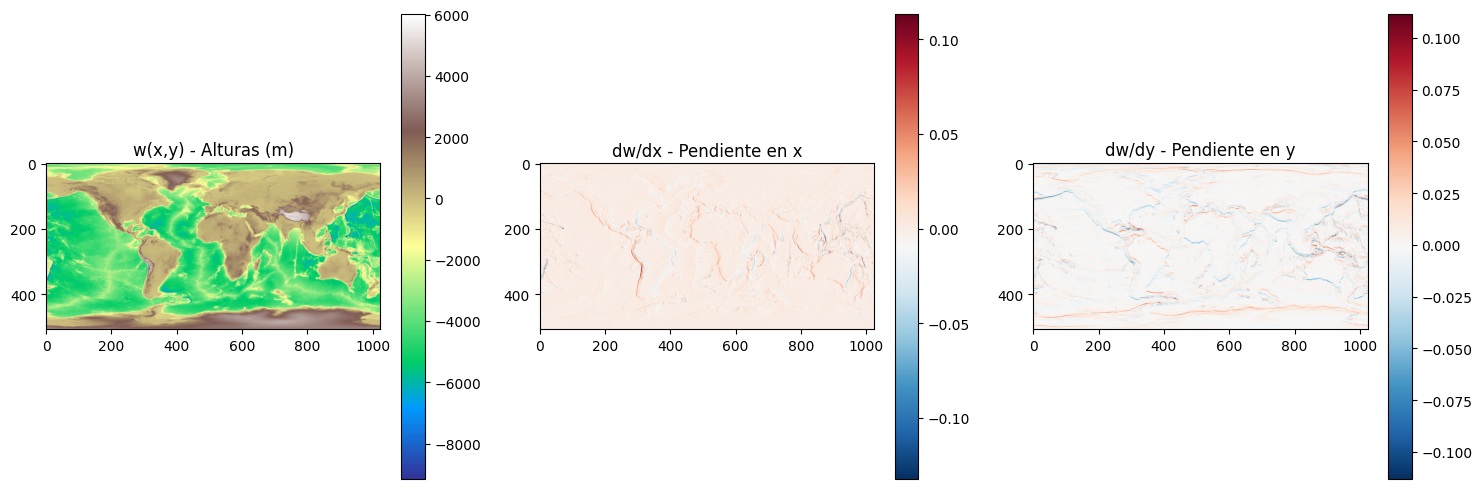

In [169]:
# FASE 7: Grafico w, dw/dx y dw/dy para verificar visualmente

fig, ax = plt.subplots(1, 3, figsize=(15, 5))  # Creo una figura con tres graficos lado a lado
im0 = ax[0].imshow(w, cmap='terrain')  # Grafico w con colormap de terreno, alto = cafe, bajo = azul
ax[0].set_title('w(x,y) - Alturas (m)')  #  titulo de las alturas
fig.colorbar(im0, ax=ax[0])  # barra de colores de las alturas
im1 = ax[1].imshow(dwdx, cmap='RdBu_r')  # Grafico dw/dx con rojo-azul, positivo = rojo, negativo = azul
ax[1].set_title('dw/dx - Pendiente en x')  #  titulo de la pendiente en x
fig.colorbar(im1, ax=ax[1])  # barra de colores de dw/dx
im2 = ax[2].imshow(dwdy, cmap='RdBu_r')  # Grafico dw/dy con rojo-azul
ax[2].set_title('dw/dy - Pendiente en y')  #  titulo de la pendiente en y
fig.colorbar(im2, ax=ax[2])  # barra de colores de dw/dy
plt.tight_layout()  # Ajusto los graficos para que no se corten los titulos
plt.show()  # Muestro los graficos


La primera gráfica muestra las alturas `w(x,y)`. 
Los colores verdes y azules indican las zonas bajas y el mar, y los colores cafés indican las montañas.

La segunda gráfica muestra la pendiente en `x` y la tercera muestra la pendiente en `y`. 
Los colores rojos y azules indican donde la altura cambia rápido, como en las costas y las cordilleras, y el color blanco indica donde el terreno es plano.

### (b)

Con los datos del inciso (a), calcula la intensidad $I$ en cada punto para luz horizontal con $\phi = 45°$:

$$ I = \frac{\cos\phi \, (\partial w / \partial x) + \sin\phi \, (\partial w / \partial y)}{\sqrt{(\partial w / \partial x)^2 + (\partial w / \partial y)^2 + 1}} $$

Grafica $I$ como imagen en escala de grises.

In [184]:
# FASE 2: Leo archivo y guardo en matriz
w = np.loadtxt('altitudes.txt')  # se len altitudes.txt y guardo alturas en matriz w
print(f"Tamano de la matriz: {w.shape}")  # imprimo tamano para verificar filas y columnas
print(f"Altura min {w.min():.2f} m, max {w.max():.2f} m")  # imprimo rango para verificar que son alturas reales

# FASE 3: Defino parametros del problema
h = 30000.0  # pongo h=30000 m, es la distancia entre puntos de la cuadricula
phi = np.deg2rad(45)  # convierto 45 grados a radianes, phi es el angulo de la luz

# FASE 4: Calculo derivadas parciales con diferencias centrales
dw_dy, dw_dx = np.gradient(w, h, h)  # calculo dw/dy y dw/dx con np.gradient

# FASE 5: Calculo intensidad de cada punto
cos_phi = np.cos(phi)  # calculo cos(phi) para la componente x de la luz
sin_phi = np.sin(phi)  # calculo sin(phi) para la componente y de la luz
numerador = cos_phi * dw_dx + sin_phi * dw_dy  # calculo numerador, es el producto punto luz-normal
denominador = np.sqrt(dw_dx**2 + dw_dy**2 + 1)  # calculo denominador, es el modulo del gradiente
I = numerador / denominador  # calculo intensidad I, va de -1 a +1

Tamano de la matriz: (508, 1024)
Altura min -9153.17 m, max 6023.26 m


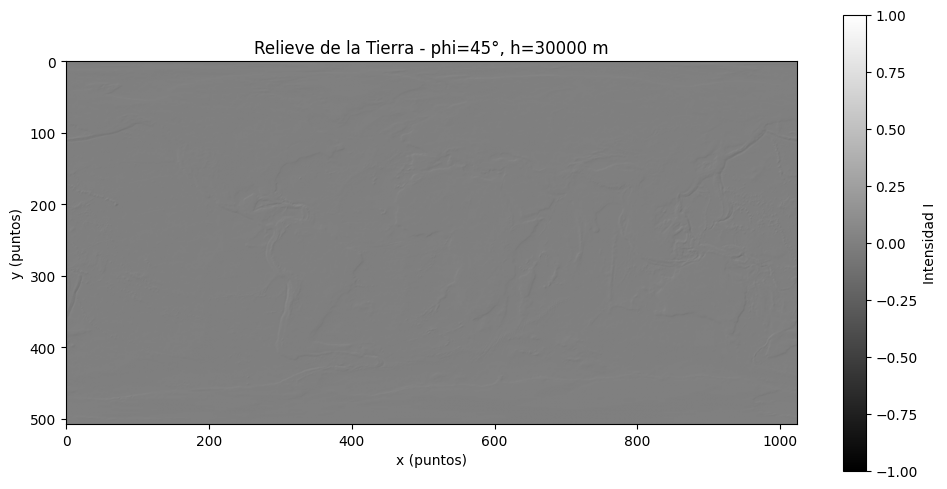

In [185]:


# FASE 6: Grafico imagen de densidad en relieve
plt.figure(figsize=(10, 5))  # creo figura de 10 por 5 pulgadas
plt.imshow(I, cmap='gray', vmin=-1, vmax=1)  # grafico I en escala de grises, -1 negro, +1 blanco
plt.colorbar(label='Intensidad I')  # muestro barra de colores con etiqueta
plt.title('Relieve de la Tierra - phi=45°, h=30000 m')  # pongo titulo de la grafica
plt.xlabel('x (puntos)')  # pongo etiqueta del eje x
plt.ylabel('y (puntos)')  # pongo etiqueta del eje y
plt.tight_layout()  # ajusto espacios para que no se corte la barra
plt.show()  # muestro grafica

### (c)

El otro archivo `stm.txt` contiene una cuadrícula de valores medidos con un microscopio STM de la superficie de silicio (111). El STM mide la forma de la superficie a nivel atómico recorriendo una punta afilada sobre la superficie y midiendo la corriente de túnel en función de la posición. Los datos del archivo contienen la rejilla de valores $w(x,y)$ de la altura de la superficie. Modifica tu programa anterior para visualizar los datos STM y crear una imagen en 3D de cómo se ve la superficie de silicio. Toma las derivadas en este caso alrededor de $h = 2.5$ en unidades arbitrarias.

In [171]:
# FASE 0: Importo  librerias 
import numpy as np  #  para trabajar con arreglos y operaciones vectoriales
import matplotlib.pyplot as plt 
import math  # Yo importo math para usar cos y sin en radianes

In [172]:
# FASE 1: Cargo el archivo del STM como matriz w(x,y)
w = np.loadtxt('stm.txt')  #  cargo el archivo stm.txt y lo guardo como matriz w


In [173]:
# FASE 2: Defino el espaciamiento real entre puntos
#  cambio h porque ahora la superficie es microscopica, no es la Tierra
h = 2.5  #  defino h = 2.5, es la distancia real entre dos puntos vecinos en el STM
ny, nx = w.shape  #  obtengo el tamano de la matriz, ny renglones en y, nx columnas en x

In [174]:
# FASE 3: Creo las matrices vacias para las derivadas
dwdx = np.zeros_like(w)  #  matriz vacia dwdx del mismo tamano que w
dwdy = np.zeros_like(w)  #  matriz vacia dwdy del mismo tamano que w

In [175]:
# FASE 4: Calculo dw/dx con diferencia central adentro y adelante/atras en los bordes
dwdx[:, 1:-1] = (w[:, 2:] - w[:, :-2]) / (2 * h)  # calculo dw/dx en el interior con diferencia central
dwdx[:, 0] = (w[:, 1] - w[:, 0]) / h  #  dw/dx en el borde izquierdo con diferencia hacia adelante
dwdx[:, -1] = (w[:, -1] - w[:, -2]) / h  # dw/dx en el borde derecho con diferencia hacia atras

In [176]:
# FASE 5: Calculo dw/dy con diferencia central adentro y adelante/atras en los bordes

dwdy[1:-1, :] = (w[2:, :] - w[:-2, :]) / (2 * h)  # dw/dy en el interior con diferencia central
dwdy[0, :] = (w[1, :] - w[0, :]) / h  # dw/dy en el borde inferior con diferencia hacia adelante
dwdy[-1, :] = (w[-1, :] - w[-2, :]) / h  # dw/dy en el borde superior con diferencia hacia atras

In [177]:
# FASE 6: Defino el angulo de la luz phi
phi = math.radians(45)  #  convierto 45 grados a radianes y lo guardo en phi

In [178]:
# FASE 7: Calculo la intensidad I en cada punto
I = (np.cos(phi) * dwdx + np.sin(phi) * dwdy) / np.sqrt(dwdx**2 + dwdy**2 + 1)  #  I 
print('I min:', np.min(I), 'I max:', np.max(I))  # imprimo min y max para verificar que I esta entre -1 y 1

I min: -0.5269887337873198 I max: 0.705239599090196


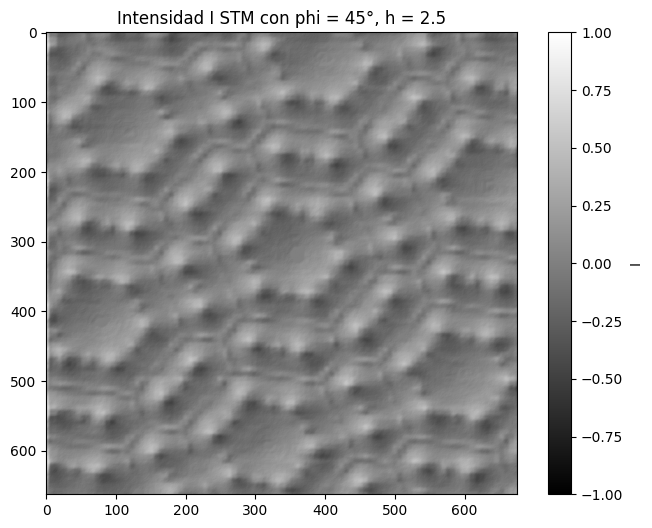

In [179]:
# FASE 8: Grafico la intensidad en escala de grises
plt.figure(figsize=(8, 6))  #  figura del mapa
plt.imshow(I, cmap='gray', vmin=-1, vmax=1)  #  I en grises, de -1 a 1
plt.title('Intensidad I STM con phi = 45°, h = 2.5')  
plt.colorbar(label='I')  #  barra de colores de I
plt.show()  

### 4. Derivación mediante integración

Escribe un programa que calcule las primeras veinte derivadas de $f(z) = e^{2z}$ en $z = 0$ utilizando la ecuación (1) con $N = 10000$.

$$ \left( \frac{d^m f}{dz^m} \right)_{z=0} \approx \frac{m!}{N} \sum_{k=0}^{N-1} f(z_k) \, e^{-i 2\pi m k / N} \frac{1}{R^m} \tag{1} $$

donde $z_k = z_0 + R \, e^{i 2\pi k / N}$, con $z_0 = 0$ y $R = 1$.

Usa la función `exp` del paquete `cmath`, que admite argumentos complejos. También te puede resultar útil la función `factorial` del paquete `math`, que calcula factoriales de argumentos enteros.

Es fácil demostrar que el valor exacto es $2^m$. Por tanto, resulta sencillo de comprobar si tu programa funciona correctamente. Notarás, mediante esta técnica, que es posible obtener resultados razonablemente precisos para las veinte derivadas de forma rápida.

In [89]:
# Fase 1
import cmath  # Importo cmath porque maneja exponenciales con numeros complejos
import math   # Importo math  uso factorial para m!

In [181]:
# Fase 2: Defino los parametros del problema
N = 10000  #N = 10000 puntos sobre el contorno circular
z0 = 0j    # z0 = 0, es el punto donde calculo las derivadas

In [182]:
# Fase 3: Defino la funcion que voy a derivar
def f(z):  # Defino la funcion f(z)
    return cmath.exp(2 * z)  # Calculo f(z) = e^(2z) con exp compleja

# Fase 4: Imprimo el encabezado de la tabla de resultados
print(f"{'m':>3} {'Numerico':>22} {'Exacto 2^m':>12} {'Error rel.':>12}")  

  m               Numerico   Exacto 2^m   Error rel.


In [183]:
# Fase 5: Calculo las primeras 20 derivadas con la formula (1)
for m in range(20):  # Recorro m = 0, 1, ..., 19,
    suma = 0j  # Inicializo la suma en cero complejo
    for k in range(N):  # Recorro los N puntos del contorno circular
        zk = cmath.exp(2j * cmath.pi * k / N)  # Calculo el punto zk  sobre el circulo unidad
        suma += f(zk) * cmath.exp(-2j * cmath.pi * k * m / N)  # Sumo f(zk) * e^(-2*pi*i*k*m/N)
    deriv = math.factorial(m) / N * suma  # Calculo la derivada con (m! / N) * suma
    exacto = 2 ** m  # Calculo el valor exacto, que es 2^m
    err = abs(deriv.real - exacto) / exacto if exacto != 0 else abs(deriv.real)  # Calculo el error relativo
    print(f"{m:>3} {deriv.real:>22.6f} {exacto:>12} {err:>12.2e}")  # Imprimo m, valor numerico, exacto y error

  0               1.000000            1     2.00e-15
  1               2.000000            2     3.77e-15
  2               4.000000            4     2.55e-15
  3               8.000000            8     2.22e-16
  4              16.000000           16     1.11e-15
  5              32.000000           32     8.88e-16
  6              64.000000           64     4.00e-15
  7             128.000000          128     1.31e-14
  8             256.000000          256     4.32e-14
  9             512.000000          512     1.51e-13
 10            1024.000000         1024     5.97e-13
 11            2048.000000         2048     2.39e-12
 12            4096.000000         4096     7.10e-11
 13            8191.999998         8192     3.01e-10
 14           16383.999966        16384     2.09e-09
 15           32767.999500        32768     1.53e-08
 16           65535.995606        65536     6.71e-08
 17          131071.937841       131072     4.74e-07
 18          262142.831017       262144     4.